## Task 1 — Data Import & Setup

In [1]:
import os
import re
import string
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", lambda value: f"{value:,.3f}")

file_name = "social_media_engagement_5000.csv"

if not os.path.exists(file_name):
    try:
        from google.colab import files
        uploaded = files.upload()
        file_name = next(iter(uploaded))
    except ImportError:
        raise FileNotFoundError(
            "Please place social_media_engagement_5000.csv in the same folder as this notebook."
        )

df = pd.read_csv(file_name)

print("Dataset imported successfully.")
print("Rows and columns:", df.shape)
display(df.head())

Dataset imported successfully.
Rows and columns: (5000, 19)


,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate
0,25795,43.000,Female,Brazil,496713,image,fitness,"7,011.000",354.000,"1,157.000",5726,44650,17-12-2022,81734,False,mobile,negative,#foodie #travel #love,0.191
1,10860,33.000,Male,Brazil,157326,reel,food,"11,750.000","2,606.000","1,807.000",5947,80216,02-06-2023,5963,False,mobile,negative,#fitness,0.201
2,86820,32.000,Female,UK,109864,text,food,"4,862.000",344.000,955.000,6946,44858,07-05-2023,501783,False,tablet,positive,#foodie,0.137
3,64886,51.000,Other,France,848877,text,fitness,"5,350.000","1,083.000","1,049.000",229,70455,12-02-2023,480212,False,mobile,negative,#music #foodie #fun,0.106
4,16265,34.000,Other,UK,449706,image,fitness,"12,682.000","2,735.000","1,300.000",4798,6019,23-05-2023,383936,False,mobile,negative,#travel,2.777


In [2]:
# Check and convert data types
print("Data types before conversion:")
display(df.dtypes.to_frame("Data Type"))

df["posted_at"] = pd.to_datetime(
    df["posted_at"], format="%d-%m-%Y", errors="coerce"
)

numeric_columns = [
    "age", "likes", "comments", "shares", "watch_time_sec",
    "impression_count", "follower_count", "engagement_rate"
]
for column in numeric_columns:
    df[column] = pd.to_numeric(df[column], errors="coerce")

print("Data types after conversion:")
display(df.dtypes.to_frame("Data Type"))

# NumPy array operations
likes_array = df["likes"].to_numpy(dtype=float)
print("First 10 likes values:", likes_array[:10])
print("Average likes:", np.nanmean(likes_array))
print("Maximum likes:", np.nanmax(likes_array))
print("Number of likes greater than 10,000:", np.sum(likes_array > 10000))

Data types before conversion:


,Data Type
user_id,int64
age,float64
gender,str
country,str
post_id,int64
post_type,str
post_category,str
likes,float64
comments,float64
shares,float64


Data types after conversion:


,Data Type
user_id,int64
age,float64
gender,str
country,str
post_id,int64
post_type,str
post_category,str
likes,float64
comments,float64
shares,float64


First 10 likes values: [ 7011. 11750.  4862.  5350. 12682. 12535. 11703.  9611.    nan 14106.]
Average likes: 10107.043711340206
Maximum likes: 19998.0
Number of likes greater than 10,000: 2455


## Task 2 — Data Cleaning

In [3]:
# Detect missing values using isnull() and isna()
print("Missing values using isnull():")
display(df.isnull().sum().to_frame("Missing Values"))

print("Missing values using isna():")
display(df.isna().sum().to_frame("Missing Values"))

print("Total missing cells:", int(df.isna().sum().sum()))
print("Duplicate rows before cleaning:", int(df.duplicated().sum()))

# Remove exact duplicate rows
data = df.drop_duplicates().copy()

# Demonstrate dropna() for records missing essential identifiers/date
rows_before_dropna = len(data)
data = data.dropna(subset=["user_id", "post_id", "posted_at"])
print("Rows removed for missing essential fields:", rows_before_dropna - len(data))

# Fill numeric missing values with median
numeric_fill_columns = [
    "age", "likes", "comments", "shares", "engagement_rate"
]
for column in numeric_fill_columns:
    data[column] = data[column].fillna(data[column].median())

# Fill categorical missing values with mode
for column in ["gender", "sentiment"]:
    data[column] = data[column].fillna(data[column].mode(dropna=True).iloc[0])

# Demonstrate forward-fill and backward-fill on date-sorted sentiment copies.
# The main cleaned dataset uses mode imputation for missing sentiment.
sentiment_sorted = data.sort_values("posted_at").copy()
sentiment_sorted["sentiment_forward_filled"] = sentiment_sorted["sentiment"].ffill()
sentiment_sorted["sentiment_backward_filled"] = sentiment_sorted["sentiment"].bfill()
display(sentiment_sorted[[
    "posted_at", "sentiment",
    "sentiment_forward_filled", "sentiment_backward_filled"
]].head())

print("Missing values after imputation:")
display(data.isna().sum().to_frame("Missing Values"))

Missing values using isnull():


,Missing Values
user_id,0
age,150
gender,150
country,0
post_id,0
post_type,0
post_category,0
likes,150
comments,150
shares,150


Missing values using isna():


,Missing Values
user_id,0
age,150
gender,150
country,0
post_id,0
post_type,0
post_category,0
likes,150
comments,150
shares,150


Total missing cells: 900
Duplicate rows before cleaning: 0
Rows removed for missing essential fields: 0


,posted_at,sentiment,sentiment_forward_filled,sentiment_backward_filled
3876,2022-01-01,positive,positive,positive
3944,2022-01-01,negative,negative,negative
2891,2022-01-01,neutral,neutral,neutral
1044,2022-01-01,positive,positive,positive
570,2022-01-01,negative,negative,negative


Missing values after imputation:


,Missing Values
user_id,0
age,0
gender,0
country,0
post_id,0
post_type,0
post_category,0
likes,0
comments,0
shares,0


In [4]:
# Standardize text categories and labels
text_columns = [
    "gender", "country", "post_type", "post_category",
    "device_type", "sentiment"
]

for column in text_columns:
    data[column] = data[column].astype("string").str.strip().str.lower()

# Standardize common gender label variations
data["gender"] = data["gender"].replace({
    "m": "male", "man": "male",
    "f": "female", "woman": "female"
})

# Standardize sentiment labels
data["sentiment"] = data["sentiment"].replace({
    "pos": "positive",
    "neg": "negative",
    "neu": "neutral"
})

# Clean hashtags: lowercase, remove punctuation other than #, normalize spaces
def clean_hashtag_text(text):
    text = "" if pd.isna(text) else str(text).lower()
    text = re.sub(r"[^#a-z0-9_\s]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

data["hashtags"] = data["hashtags"].apply(clean_hashtag_text)

# Correct unrealistic negative engagement values if present
engagement_columns = [
    "likes", "comments", "shares", "watch_time_sec",
    "impression_count", "follower_count"
]
for column in engagement_columns:
    invalid_count = int((data[column] < 0).sum())
    print(f"Negative values in {column}:", invalid_count)
    if invalid_count:
        data.loc[data[column] < 0, column] = np.nan
        data[column] = data[column].fillna(data[column].median())

# Extract hashtag count
data["hashtag_count"] = data["hashtags"].apply(
    lambda text: len(re.findall(r"(?<!\w)#\w+", text))
)

print("Cleaned dataset shape:", data.shape)
print("Duplicate rows after cleaning:", int(data.duplicated().sum()))
display(data.head())

Negative values in likes: 0
Negative values in comments: 0
Negative values in shares: 0
Negative values in watch_time_sec: 0
Negative values in impression_count: 0
Negative values in follower_count: 0
Cleaned dataset shape: (5000, 20)
Duplicate rows after cleaning: 0


,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate,hashtag_count
0,25795,43.000,female,brazil,496713,image,fitness,"7,011.000",354.000,"1,157.000",5726,44650,2022-12-17,81734,False,mobile,negative,#foodie #travel #love,0.191,3
1,10860,33.000,male,brazil,157326,reel,food,"11,750.000","2,606.000","1,807.000",5947,80216,2023-06-02,5963,False,mobile,negative,#fitness,0.201,1
2,86820,32.000,female,uk,109864,text,food,"4,862.000",344.000,955.000,6946,44858,2023-05-07,501783,False,tablet,positive,#foodie,0.137,1
3,64886,51.000,other,france,848877,text,fitness,"5,350.000","1,083.000","1,049.000",229,70455,2023-02-12,480212,False,mobile,negative,#music #foodie #fun,0.106,3
4,16265,34.000,other,uk,449706,image,fitness,"12,682.000","2,735.000","1,300.000",4798,6019,2023-05-23,383936,False,mobile,negative,#travel,2.777,1


## Task 3 — Data Exploration Using Pandas

In [5]:
# View dataset structure using head(), tail(), shape and columns
print("First five rows:")
display(data.head())

print("Last five rows:")
display(data.tail())

print("Dataset shape:", data.shape)
print("Column names:")
print(data.columns.tolist())

# Check info() and dtypes
print("Dataset information:")
data.info()

print("Data types:")
display(data.dtypes.to_frame("Data Type"))

# Summary statistics
display(data.describe(include="all").T)

First five rows:


,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate,hashtag_count
0,25795,43.000,female,brazil,496713,image,fitness,"7,011.000",354.000,"1,157.000",5726,44650,2022-12-17,81734,False,mobile,negative,#foodie #travel #love,0.191,3
1,10860,33.000,male,brazil,157326,reel,food,"11,750.000","2,606.000","1,807.000",5947,80216,2023-06-02,5963,False,mobile,negative,#fitness,0.201,1
2,86820,32.000,female,uk,109864,text,food,"4,862.000",344.000,955.000,6946,44858,2023-05-07,501783,False,tablet,positive,#foodie,0.137,1
3,64886,51.000,other,france,848877,text,fitness,"5,350.000","1,083.000","1,049.000",229,70455,2023-02-12,480212,False,mobile,negative,#music #foodie #fun,0.106,3
4,16265,34.000,other,uk,449706,image,fitness,"12,682.000","2,735.000","1,300.000",4798,6019,2023-05-23,383936,False,mobile,negative,#travel,2.777,1


Last five rows:


,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate,hashtag_count
4995,59500,44.000,male,australia,441541,video,education,"16,210.000","2,013.000","1,837.000",6190,42977,2022-06-25,646147,False,mobile,positive,#travel #fun,0.467,2
4996,22100,38.000,other,uae,677076,reel,education,"16,924.000","2,734.000","1,583.000",7764,34196,2022-11-18,584603,False,desktop,negative,#foodie #reels,0.621,2
4997,67021,63.000,female,usa,273595,text,travel,"13,487.000","1,497.000",167.000,7466,23680,2023-04-06,483550,False,desktop,positive,#lifestyle #tech,0.680,2
4998,29800,13.000,female,germany,785644,video,fitness,"16,894.000","1,289.000","1,713.000",4991,89013,2022-05-16,183295,False,tablet,positive,#reels #love #fitness,0.224,3
4999,73400,54.000,other,japan,712252,text,travel,"14,830.000",503.000,"1,798.000",3743,14234,2023-03-04,585760,False,desktop,neutral,#foodie #lifestyle #fashion,1.204,3


Dataset shape: (5000, 20)
Column names:
['user_id', 'age', 'gender', 'country', 'post_id', 'post_type', 'post_category', 'likes', 'comments', 'shares', 'watch_time_sec', 'impression_count', 'posted_at', 'follower_count', 'is_verified', 'device_type', 'sentiment', 'hashtags', 'engagement_rate', 'hashtag_count']
Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   user_id           5000 non-null   int64         
 1   age               5000 non-null   float64       
 2   gender            5000 non-null   string        
 3   country           5000 non-null   string        
 4   post_id           5000 non-null   int64         
 5   post_type         5000 non-null   string        
 6   post_category     5000 non-null   string        
 7   likes             5000 non-null   float64       
 8   comments          5000 non

,Data Type
user_id,int64
age,float64
gender,string
country,string
post_id,int64
post_type,string
post_category,string
likes,float64
comments,float64
shares,float64


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
user_id,"5,000.000",NaN,NaN,NaN,"54,561.891","10,055.000","32,309.500","54,374.500","77,180.500","99,963.000","26,090.370"
age,"5,000.000",NaN,NaN,NaN,38.440,13.000,26.000,38.000,51.000,64.000,14.687
gender,5000,3,male,1849,NaN,NaN,NaN,NaN,NaN,NaN,NaN
country,5000,10,india,535,NaN,NaN,NaN,NaN,NaN,NaN,NaN
post_id,"5,000.000",NaN,NaN,NaN,"548,042.909","100,068.000","322,543.500","548,077.500","771,574.500","999,455.000","260,646.957"
post_type,5000,4,reel,1283,NaN,NaN,NaN,NaN,NaN,NaN,NaN
post_category,5000,8,fitness,675,NaN,NaN,NaN,NaN,NaN,NaN,NaN
likes,"5,000.000",NaN,NaN,NaN,"10,106.997",10.000,"5,235.000","10,105.500","14,959.000","19,998.000","5,702.293"
comments,"5,000.000",NaN,NaN,NaN,"1,502.040",0.000,792.000,"1,497.000","2,235.250","2,999.000",856.393
shares,"5,000.000",NaN,NaN,NaN,"1,002.911",0.000,511.000,"1,012.000","1,483.000","1,999.000",570.855


In [6]:
# Categorical distributions using value_counts(), unique() and nunique()
categorical_columns = [
    "gender", "country", "post_type", "post_category",
    "device_type", "sentiment", "is_verified"
]

for column in categorical_columns:
    print(f"\n{column.upper()} — VALUE COUNTS")
    display(data[column].value_counts(dropna=False).to_frame("Count"))
    print("Unique values:", data[column].unique())
    print("Number of unique values:", data[column].nunique())


GENDER — VALUE COUNTS


,Count
gender,
male,1849
other,1581
female,1570


Unique values: <ArrowStringArray>
['female', 'male', 'other']
Length: 3, dtype: string
Number of unique values: 3

COUNTRY — VALUE COUNTS


,Count
country,
india,535
canada,513
brazil,504
uae,503
usa,501
france,496
uk,493
australia,493
germany,490


Unique values: <ArrowStringArray>
['brazil', 'uk', 'france', 'canada', 'japan', 'australia', 'india', 'uae', 'germany', 'usa']
Length: 10, dtype: string
Number of unique values: 10

POST_TYPE — VALUE COUNTS


,Count
post_type,
reel,1283
image,1247
text,1245
video,1225


... (5 outputs left out)

,Count
sentiment,
positive,2513
neutral,1527
negative,960


Unique values: <ArrowStringArray>
['negative', 'positive', 'neutral']
Length: 3, dtype: string
Number of unique values: 3

IS_VERIFIED — VALUE COUNTS


,Count
is_verified,
False,4517
True,483


Unique values: [False  True]
Number of unique values: 2


In [7]:
# Correlation matrix for numeric fields
numeric_data = data.select_dtypes(include=np.number)
correlation_matrix = numeric_data.corr()
display(correlation_matrix)

,user_id,age,post_id,likes,comments,shares,watch_time_sec,impression_count,follower_count,engagement_rate,hashtag_count
user_id,1.000,-0.007,0.020,0.026,-0.033,0.014,-0.017,0.015,0.010,-0.004,-0.014
age,-0.007,1.000,-0.013,-0.036,-0.007,0.014,0.006,0.013,-0.025,0.008,0.007
post_id,0.020,-0.013,1.000,0.015,-0.011,0.002,0.018,-0.008,-0.003,0.010,0.007
likes,0.026,-0.036,0.015,1.000,-0.018,0.005,0.009,0.008,-0.023,0.094,-0.002
comments,-0.033,-0.007,-0.011,-0.018,1.000,0.006,-0.016,-0.009,-0.012,0.000,-0.015
shares,0.014,0.014,0.002,0.005,0.006,1.000,0.015,-0.005,-0.011,0.022,0.013
watch_time_sec,-0.017,0.006,0.018,0.009,-0.016,0.015,1.000,-0.004,0.003,-0.001,-0.023
impression_count,0.015,0.013,-0.008,0.008,-0.009,-0.005,-0.004,1.000,-0.016,-0.232,-0.003
follower_count,0.010,-0.025,-0.003,-0.023,-0.012,-0.011,0.003,-0.016,1.000,0.002,0.009
engagement_rate,-0.004,0.008,0.010,0.094,0.000,0.022,-0.001,-0.232,0.002,1.000,0.005


In [8]:
# Groupby summaries: average likes by post type and impressions by country
average_likes_by_post_type = (
    data.groupby("post_type")["likes"]
    .mean()
    .sort_values(ascending=False)
    .to_frame("Average Likes")
)
display(average_likes_by_post_type)

average_impressions_by_country = (
    data.groupby("country")["impression_count"]
    .mean()
    .sort_values(ascending=False)
    .to_frame("Average Impressions")
)
display(average_impressions_by_country)

,Average Likes
post_type,
video,"10,188.600"
image,"10,104.865"
text,"10,100.148"
reel,"10,037.802"


,Average Impressions
country,
india,"52,462.387"
france,"51,727.673"
usa,"51,263.872"
uk,"51,119.394"
japan,"49,616.136"
brazil,"49,193.175"
uae,"48,928.414"
canada,"48,703.150"
germany,"48,605.406"


## Task 4 — Data Wrangling

In [9]:
# Create new fields: engagement_score, log metrics and hashtag_count
data["engagement_score"] = data[["likes", "comments", "shares"]].sum(axis=1)
data["log_likes"] = np.log1p(data["likes"])
data["log_comments"] = np.log1p(data["comments"])
data["log_shares"] = np.log1p(data["shares"])
data["posted_date"] = data["posted_at"].dt.date

# Create age groups for user-trend analysis
data["age_group"] = pd.cut(
    data["age"],
    bins=[0, 18, 25, 35, 45, 55, 100],
    labels=["18 or below", "19-25", "26-35", "36-45", "46-55", "56+"],
    include_lowest=True
)

# Groupby summaries by post_type, country and sentiment
post_type_summary = data.groupby("post_type").agg(
    Post_Count=("post_id", "count"),
    Average_Likes=("likes", "mean"),
    Average_Engagement_Rate=("engagement_rate", "mean"),
    Average_Engagement_Score=("engagement_score", "mean")
).sort_values("Average_Engagement_Rate", ascending=False)

country_summary = data.groupby("country").agg(
    Post_Count=("post_id", "count"),
    Average_Impressions=("impression_count", "mean"),
    Average_Engagement_Rate=("engagement_rate", "mean")
).sort_values("Average_Engagement_Rate", ascending=False)

sentiment_summary = data.groupby("sentiment").agg(
    Post_Count=("post_id", "count"),
    Average_Engagement_Rate=("engagement_rate", "mean"),
    Average_Engagement_Score=("engagement_score", "mean")
).sort_values("Average_Engagement_Rate", ascending=False)

print("Post type summary:")
display(post_type_summary)
print("Country summary:")
display(country_summary)
print("Sentiment summary:")
display(sentiment_summary)

# No second dataset is supplied; merge/concat/join is not required.
# Sort posts by engagement for structured output.
ranked_posts = data.sort_values(
    ["engagement_rate", "engagement_score"],
    ascending=[False, False]
)[[
    "post_id", "post_type", "post_category", "country",
    "likes", "comments", "shares", "engagement_rate"
]]
display(ranked_posts.head(10))

Post type summary:


,Post_Count,Average_Likes,Average_Engagement_Rate,Average_Engagement_Score
post_type,,,,
video,1225,"10,188.600",1.122,"12,664.594"
text,1245,"10,100.148",1.065,"12,613.244"
image,1247,"10,104.865",0.896,"12,649.391"
reel,1283,"10,037.802",0.783,"12,524.032"


Country summary:


,Post_Count,Average_Impressions,Average_Engagement_Rate
country,,,
brazil,504,"49,193.175",1.541
australia,493,"48,346.383",1.324
france,496,"51,727.673",1.146
uae,503,"48,928.414",1.112
canada,513,"48,703.150",0.917
uk,493,"51,119.394",0.851
japan,472,"49,616.136",0.770
germany,490,"48,605.406",0.759
india,535,"52,462.387",0.655


Sentiment summary:


,Post_Count,Average_Engagement_Rate,Average_Engagement_Score
sentiment,,,
negative,960,1.038,"12,731.499"
neutral,1527,0.991,"12,448.164"
positive,2513,0.920,"12,665.799"


,post_id,post_type,post_category,country,likes,comments,shares,engagement_rate
554,213043,text,food,brazil,"18,513.000","2,090.000","1,420.000",191.504
144,221729,video,tech,australia,"15,055.000","1,253.000","1,616.000",121.932
1947,987996,video,food,canada,"10,652.000",409.000,889.000,105.752
541,646432,image,food,brazil,"7,736.000","1,681.000",887.000,92.829
145,787693,reel,tech,germany,"19,311.000",415.000,607.000,87.266
4181,705240,video,lifestyle,brazil,"17,045.000",688.000,91.000,77.160
2369,838587,text,music,brazil,"8,044.000",864.000,"1,807.000",68.686
2426,953539,video,music,france,"17,338.000","2,580.000","1,483.000",67.511
652,353116,video,fashion,france,"13,410.000","2,117.000",409.000,65.580
2993,372659,reel,lifestyle,uk,"6,996.000","2,972.000",922.000,61.180


## Task 5 — Statistical Analysis

In [10]:
# Mean, median, mode, standard deviation, variance and percentiles
stat_columns = [
    "likes", "comments", "shares", "watch_time_sec",
    "engagement_rate", "follower_count"
]

statistics = pd.DataFrame(index=stat_columns)
statistics["Mean"] = data[stat_columns].mean()
statistics["Median"] = data[stat_columns].median()
statistics["Mode"] = data[stat_columns].mode().iloc[0]
statistics["Standard Deviation"] = data[stat_columns].std()
statistics["Variance"] = data[stat_columns].var()
statistics["Minimum"] = data[stat_columns].min()
statistics["25th Percentile"] = data[stat_columns].quantile(0.25)
statistics["50th Percentile"] = data[stat_columns].quantile(0.50)
statistics["75th Percentile"] = data[stat_columns].quantile(0.75)
statistics["90th Percentile"] = data[stat_columns].quantile(0.90)
statistics["Maximum"] = data[stat_columns].max()
statistics["Skewness"] = data[stat_columns].skew()
statistics["Kurtosis"] = data[stat_columns].kurtosis()

display(statistics.round(3))

,Mean,Median,Mode,Standard Deviation,Variance,Minimum,25th Percentile,50th Percentile,75th Percentile,90th Percentile,Maximum,Skewness,Kurtosis
likes,"10,106.997","10,105.500","10,105.500","5,702.293","32,516,145.654",10.000,"5,235.000","10,105.500","14,959.000","18,016.300","19,998.000",-0.007,-1.150
comments,"1,502.040","1,497.000","1,497.000",856.393,"733,409.505",0.000,792.000,"1,497.000","2,235.250","2,695.100","2,999.000",0.004,-1.144
shares,"1,002.911","1,012.000","1,012.000",570.855,"325,875.659",0.000,511.000,"1,012.000","1,483.000","1,795.100","1,999.000",-0.015,-1.147
watch_time_sec,"4,014.503","4,034.500",916.000,"2,308.096","5,327,309.264",0.000,"2,017.750","4,034.500","6,020.250","7,212.100","7,998.000",-0.018,-1.196
engagement_rate,0.964,0.254,0.006,5.318,28.281,0.006,0.146,0.254,0.505,1.201,191.504,18.781,482.992
follower_count,"393,698.225","388,982.000","497,502.000","230,927.885","53,327,687,855.630",87.000,"194,480.000","388,982.000","589,744.250","717,755.900","799,533.000",0.041,-1.189


## Task 6 — Data Visualization (All Required Plot Types)

### Matplotlib

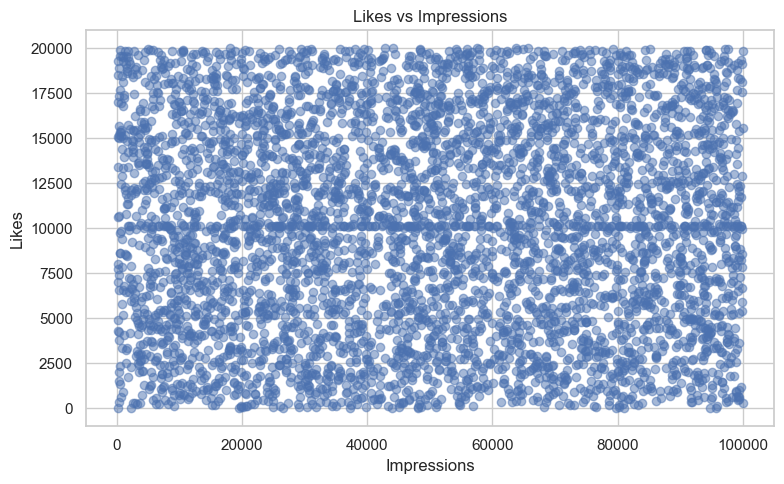

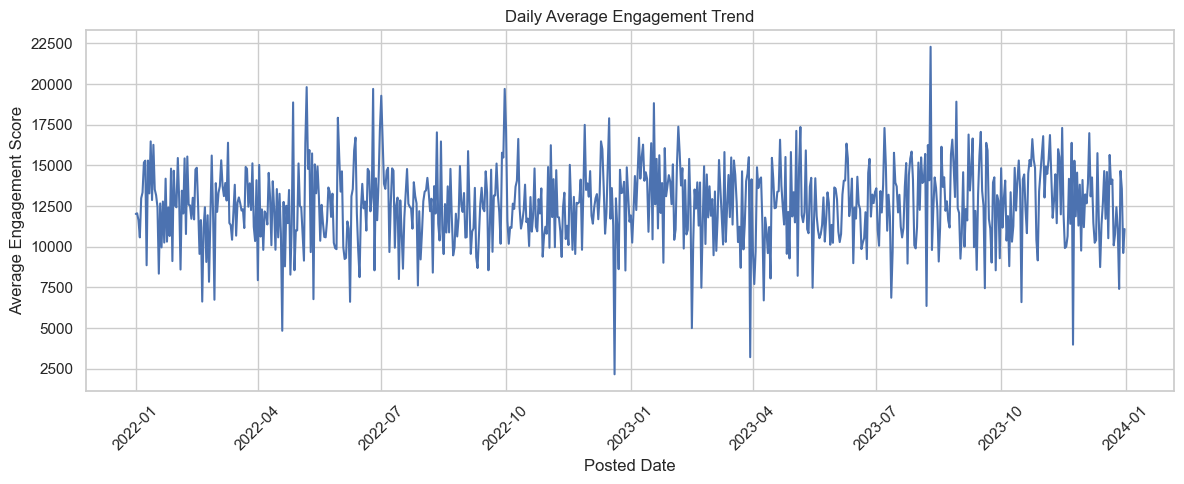

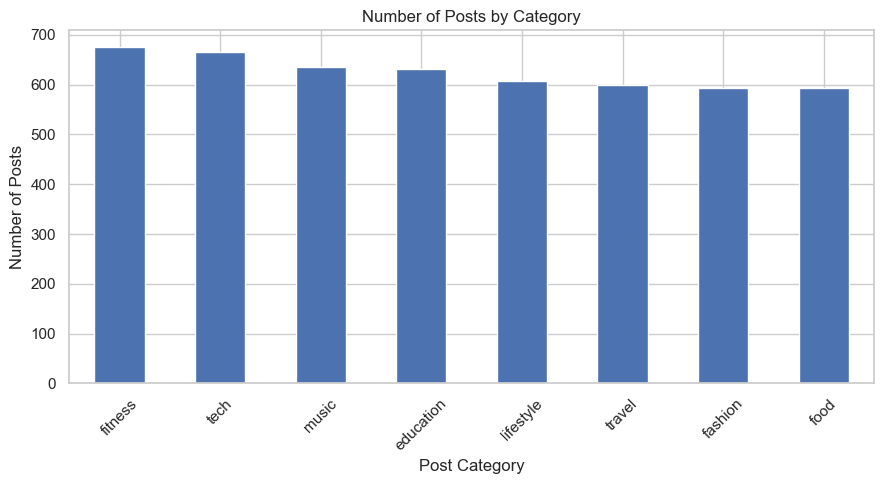

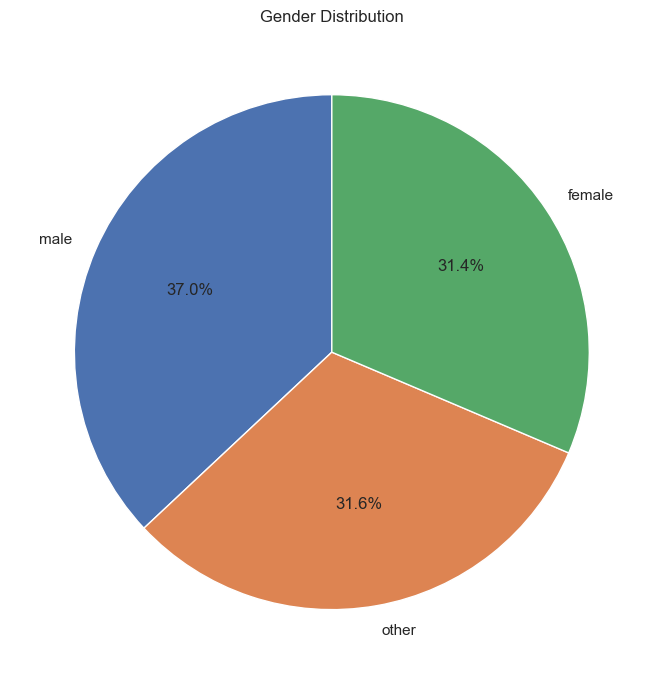

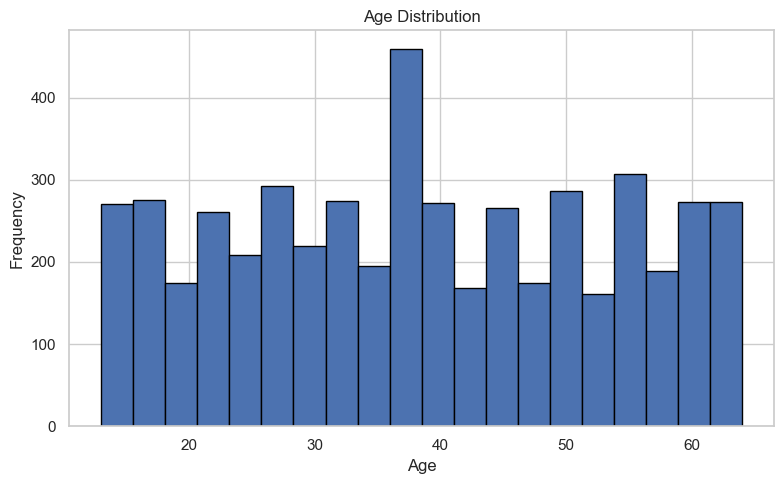

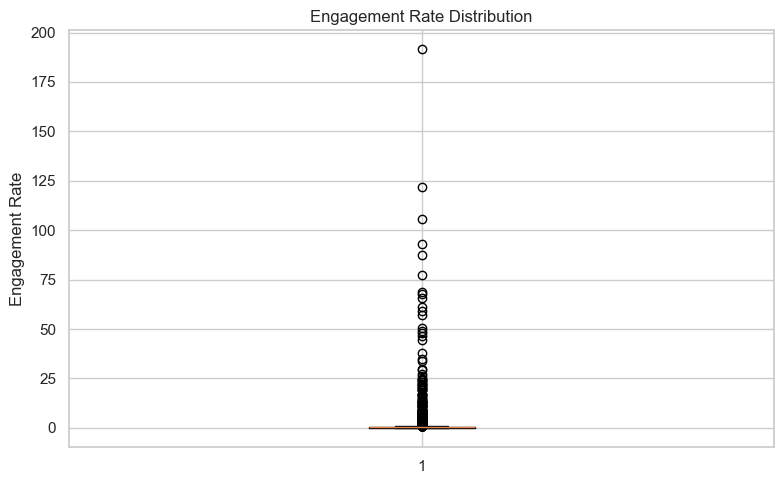

In [11]:
# 1. Scatter plot — likes vs impressions
plt.figure(figsize=(8, 5))
plt.scatter(data["impression_count"], data["likes"], alpha=0.5)
plt.title("Likes vs Impressions")
plt.xlabel("Impressions")
plt.ylabel("Likes")
plt.tight_layout()
plt.show()

# 2. Line chart — daily engagement trend
daily_engagement = data.groupby("posted_date")["engagement_score"].mean().reset_index()
daily_engagement["posted_date"] = pd.to_datetime(daily_engagement["posted_date"])

plt.figure(figsize=(12, 5))
plt.plot(daily_engagement["posted_date"], daily_engagement["engagement_score"])
plt.title("Daily Average Engagement Trend")
plt.xlabel("Posted Date")
plt.ylabel("Average Engagement Score")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# 3. Bar chart — number of posts by category
posts_by_category = data["post_category"].value_counts()
plt.figure(figsize=(9, 5))
posts_by_category.plot(kind="bar")
plt.title("Number of Posts by Category")
plt.xlabel("Post Category")
plt.ylabel("Number of Posts")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# 4. Pie chart — gender distribution
gender_counts = data["gender"].value_counts()
plt.figure(figsize=(7, 7))
plt.pie(gender_counts.values, labels=gender_counts.index, autopct="%1.1f%%", startangle=90)
plt.title("Gender Distribution")
plt.tight_layout()
plt.show()

# 5. Histogram — age distribution
plt.figure(figsize=(8, 5))
plt.hist(data["age"], bins=20, edgecolor="black")
plt.title("Age Distribution")
plt.xlabel("Age")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

# 6. Box plot — engagement rate
plt.figure(figsize=(8, 5))
plt.boxplot(data["engagement_rate"].dropna())
plt.title("Engagement Rate Distribution")
plt.ylabel("Engagement Rate")
plt.tight_layout()
plt.show()

### Seaborn

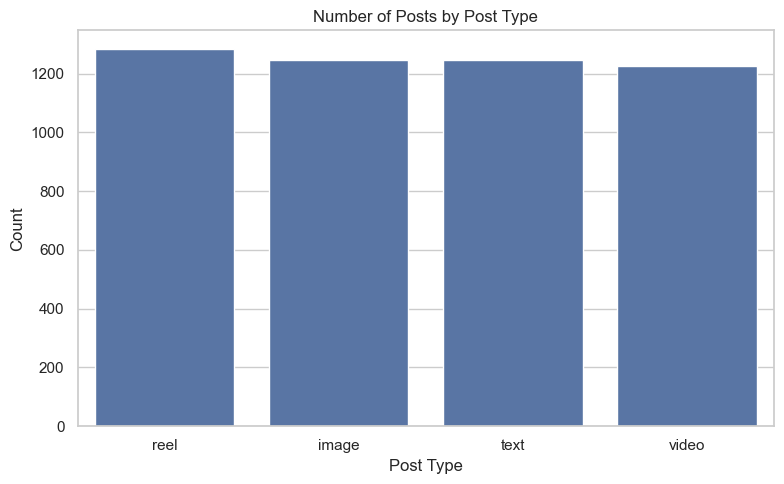

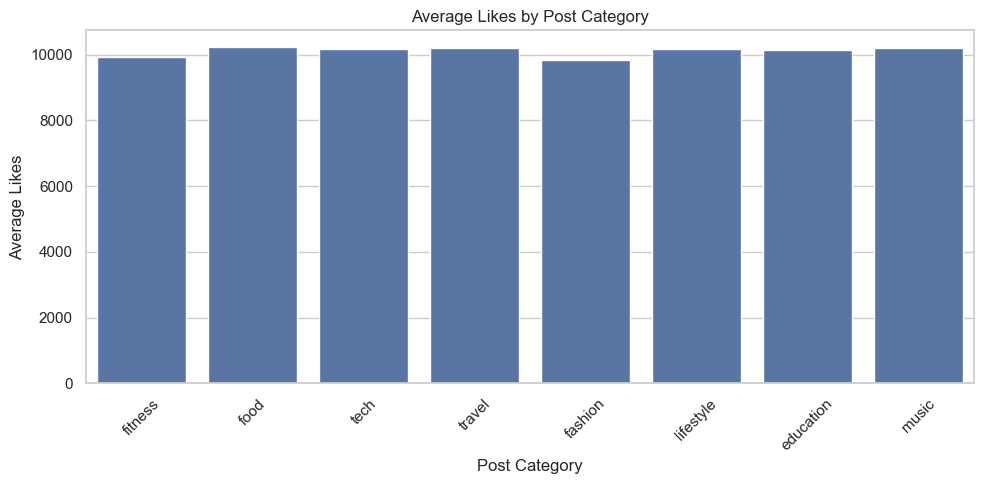

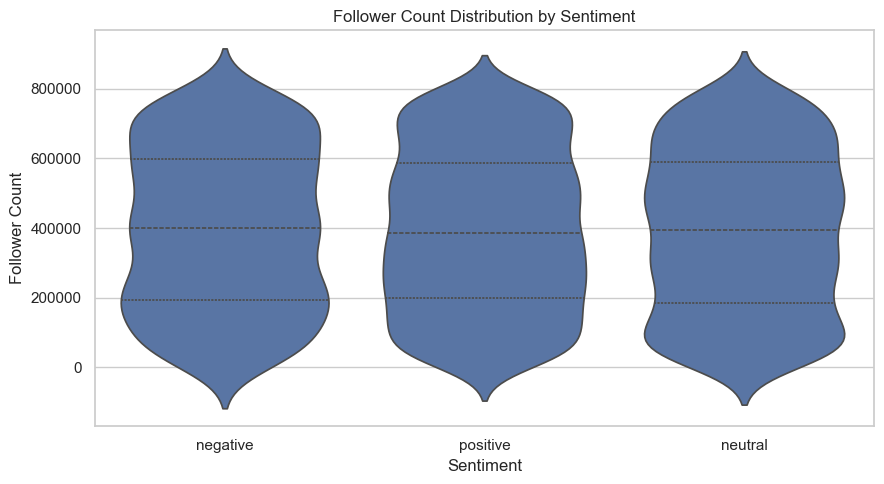

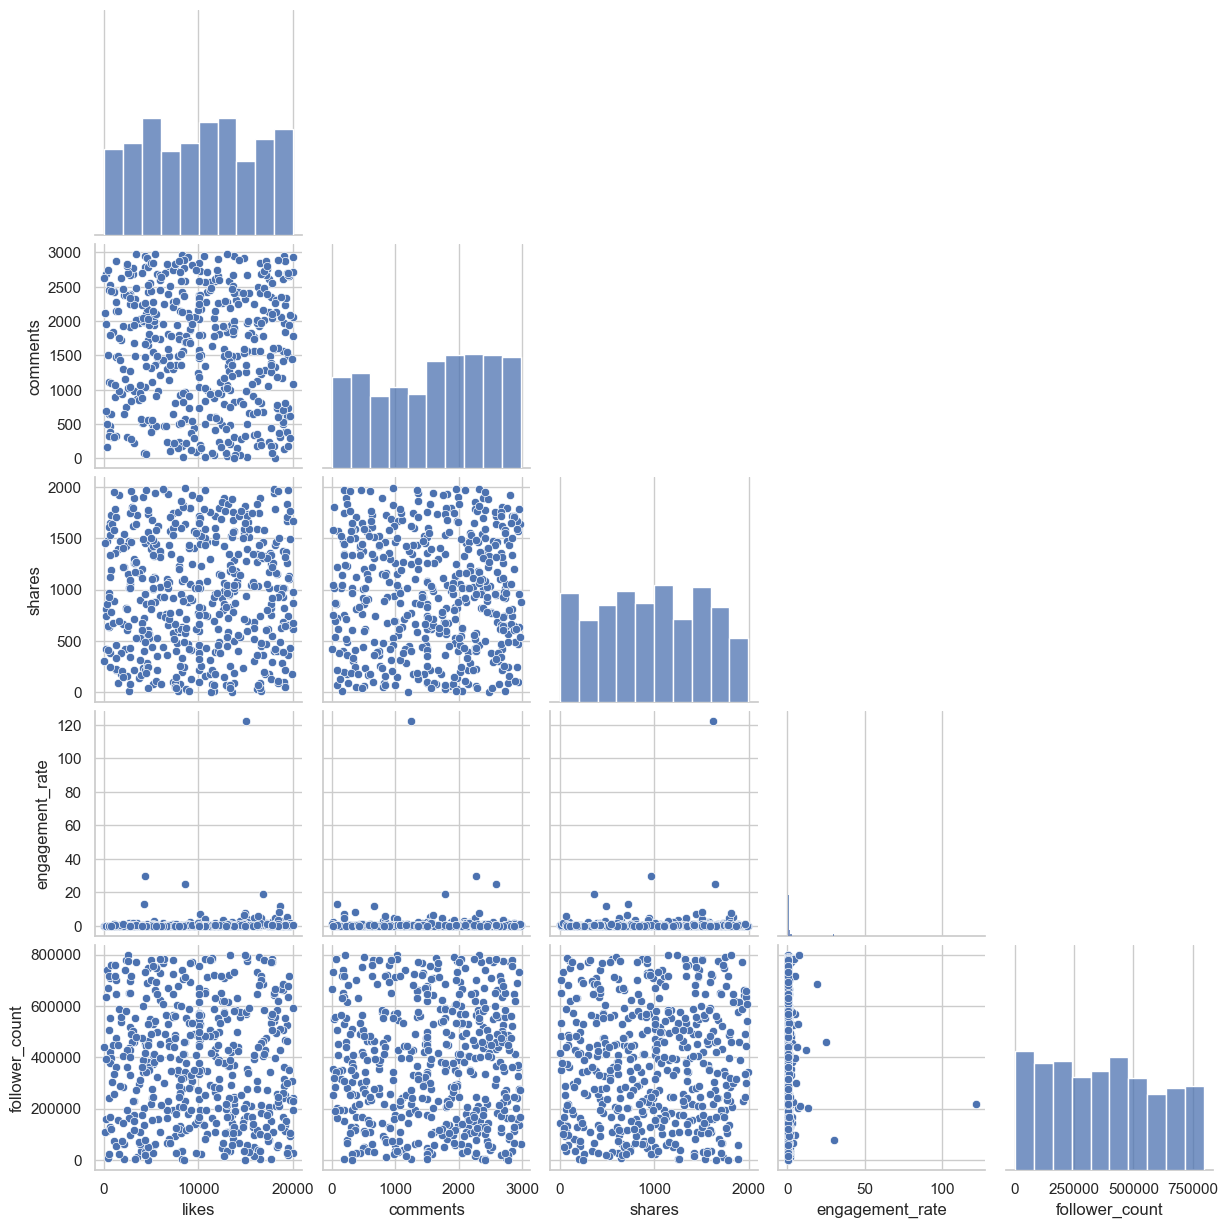

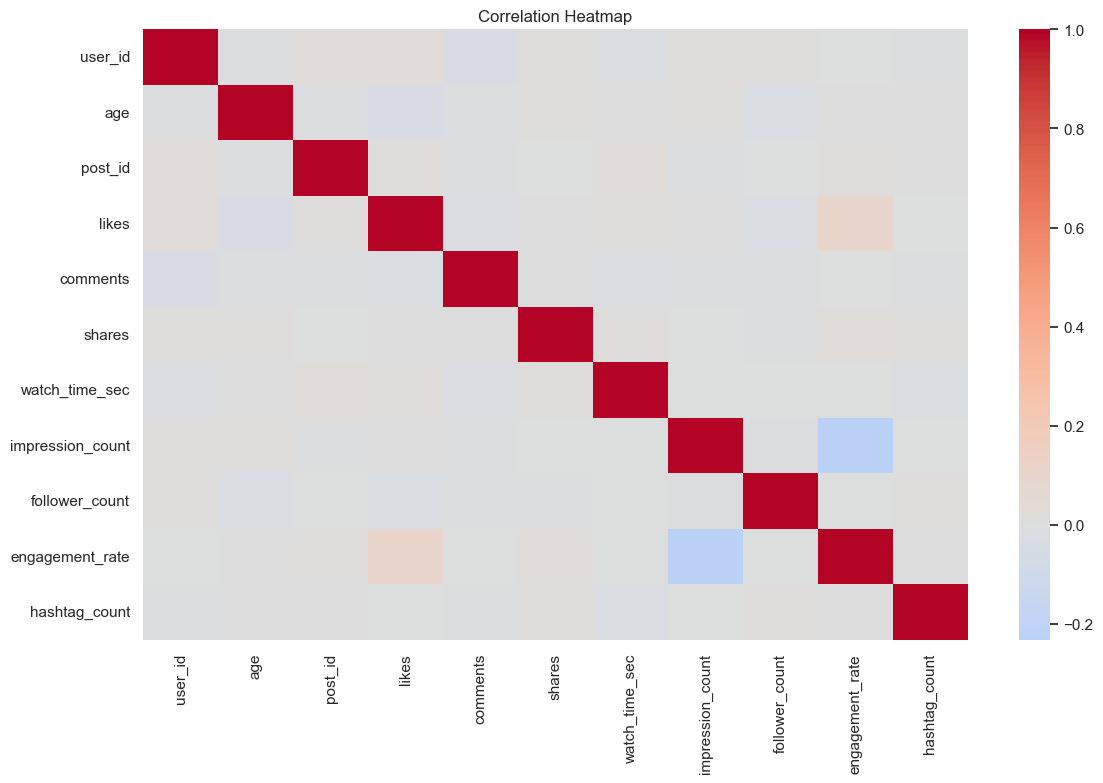

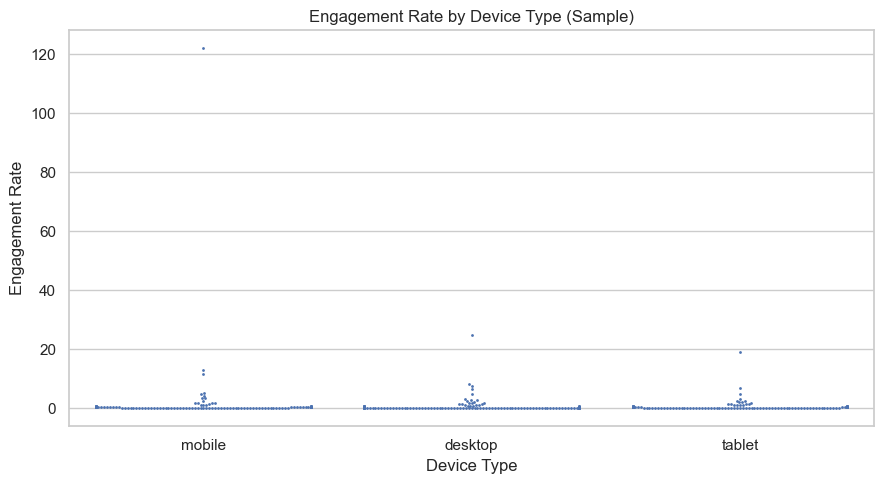

In [12]:
# 7. Count plot — post type
plt.figure(figsize=(8, 5))
sns.countplot(data=data, x="post_type", order=data["post_type"].value_counts().index)
plt.title("Number of Posts by Post Type")
plt.xlabel("Post Type")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

# 8. Bar plot — average likes by category
plt.figure(figsize=(10, 5))
sns.barplot(data=data, x="post_category", y="likes", errorbar=None)
plt.title("Average Likes by Post Category")
plt.xlabel("Post Category")
plt.ylabel("Average Likes")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# 9. Violin plot — follower count vs sentiment
plt.figure(figsize=(9, 5))
sns.violinplot(data=data, x="sentiment", y="follower_count", inner="quartile")
plt.title("Follower Count Distribution by Sentiment")
plt.xlabel("Sentiment")
plt.ylabel("Follower Count")
plt.tight_layout()
plt.show()

# 10. Pair plot — numeric features (sample for performance)
pair_columns = ["likes", "comments", "shares", "engagement_rate", "follower_count"]
pair_sample = data[pair_columns].dropna().sample(
    n=min(500, len(data[pair_columns].dropna())), random_state=42
)
sns.pairplot(pair_sample, corner=True)
plt.show()

# 11. Heatmap — correlation matrix
plt.figure(figsize=(12, 8))
sns.heatmap(correlation_matrix, cmap="coolwarm", center=0, annot=False)
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

# 12. Swarm plot — engagement vs device (sample for readability)
swarm_sample = data.sample(n=min(400, len(data)), random_state=42)
plt.figure(figsize=(9, 5))
sns.swarmplot(data=swarm_sample, x="device_type", y="engagement_rate", size=2)
plt.title("Engagement Rate by Device Type (Sample)")
plt.xlabel("Device Type")
plt.ylabel("Engagement Rate")
plt.tight_layout()
plt.show()

### Plotly — Interactive Visualizations

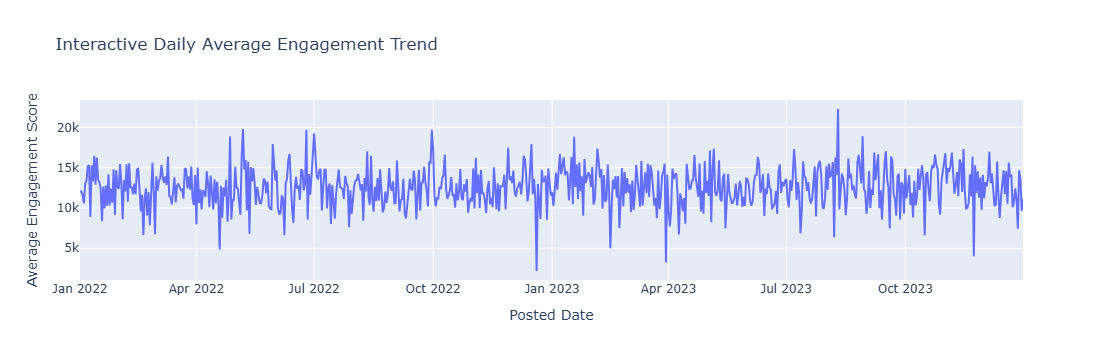

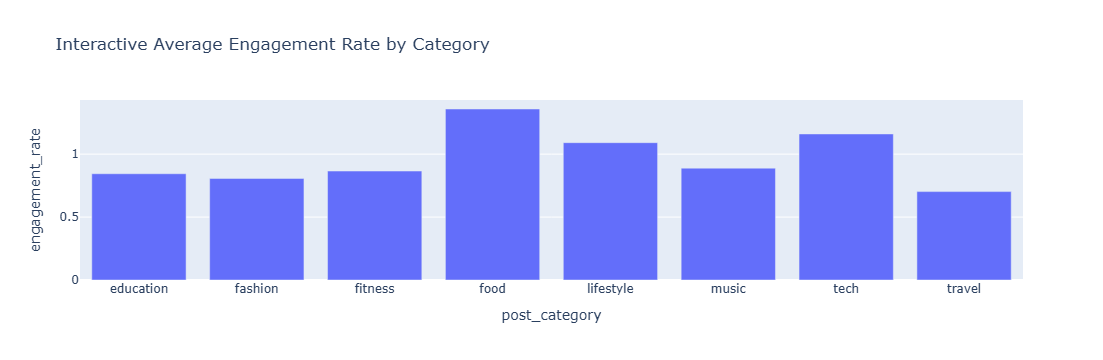

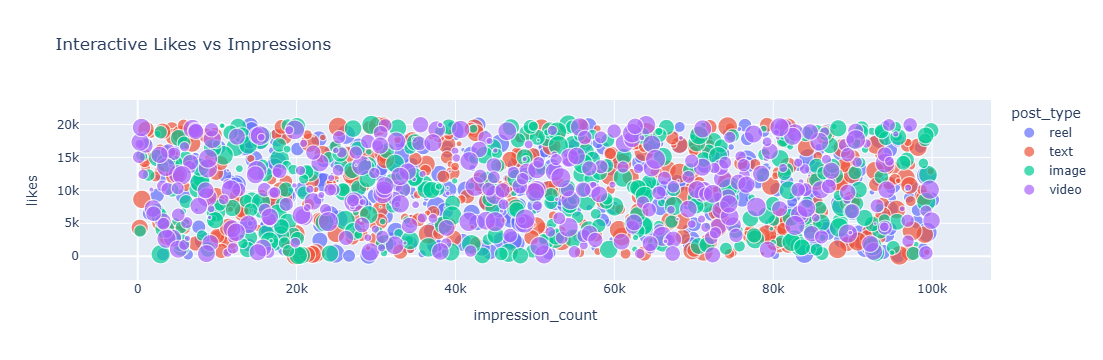

In [15]:
# 13. Interactive line chart — daily engagement trend
fig = px.line(
    daily_engagement,
    x="posted_date",
    y="engagement_score",
    title="Interactive Daily Average Engagement Trend",
    labels={"posted_date": "Posted Date", "engagement_score": "Average Engagement Score"}
)
fig.show()

# 14. Interactive bar chart — average engagement by post category
plotly_category = data.groupby("post_category", as_index=False)["engagement_rate"].mean()
fig = px.bar(
    plotly_category,
    x="post_category",
    y="engagement_rate",
    title="Interactive Average Engagement Rate by Category"
)
fig.show()

# 15. Interactive bubble/scatter chart — likes vs impressions
plotly_sample = data.sample(n=min(1500, len(data)), random_state=42)
fig = px.scatter(
    plotly_sample,
    x="impression_count",
    y="likes",
    color="post_type",
    size="comments",
    hover_data=["country", "sentiment"],
    title="Interactive Likes vs Impressions"
)
fig.show()

## Final Insights — Answers Based on the Dataset

In [19]:
# Content Performance
post_type_insights = data.groupby("post_type")["engagement_rate"].mean().sort_values(ascending=False)
category_insights = data.groupby("post_category")["engagement_rate"].mean().sort_values(ascending=False)
country_insights = data.groupby("country")["engagement_rate"].mean().sort_values(ascending=False)

print("Post types ranked by average engagement rate:")
display(post_type_insights.to_frame("Average Engagement Rate"))

print("Content categories ranked by average engagement rate:")
display(category_insights.to_frame("Average Engagement Rate"))

print("Countries ranked by average engagement rate:")
display(country_insights.to_frame("Average Engagement Rate"))

# User Trends
age_insights = data.groupby("age_group", observed=True)["engagement_rate"].mean().sort_values(ascending=False)
verified_insights = data.groupby("is_verified")["engagement_rate"].agg(["count", "mean", "median"])

print("Average engagement rate by age group:")
display(age_insights.to_frame("Average Engagement Rate"))

print("Verified account comparison:")
display(verified_insights)

# Behavioral Insights
device_insights = data.groupby("device_type")["watch_time_sec"].mean().sort_values(ascending=False)
print("Average watch time by device:")
display(device_insights.to_frame("Average Watch Time (seconds)"))

# posted_at contains date only; inspect whether time-of-day variation exists
print("Distinct recorded posting hours:", sorted(data["posted_at"].dt.hour.dropna().unique()))
if data["posted_at"].dt.hour.nunique() <= 1:
    print("Best time of day cannot be determined: posted_at contains dates without meaningful time-of-day information.")
else:
    hour_impressions = data.groupby(data["posted_at"].dt.hour)["impression_count"].mean().sort_values(ascending=False)
    print("Average impressions by hour:")
    display(hour_impressions.to_frame("Average Impressions"))

# Sentiment Analysis
sentiment_insights = data.groupby("sentiment").agg(
    Post_Count=("post_id", "count"),
    Average_Engagement_Rate=("engagement_rate", "mean"),
    Average_Engagement_Score=("engagement_score", "mean"),
    Average_Likes=("likes", "mean"),
    Average_Comments=("comments", "mean"),
    Average_Shares=("shares", "mean")
).sort_values("Average_Engagement_Rate", ascending=False)

print("Sentiment performance:")
display(sentiment_insights)

print("Negative and neutral sentiment comparison:")
display(sentiment_insights.loc[
    sentiment_insights.index.intersection(["negative", "neutral"])
])

Post types ranked by average engagement rate:


,Average Engagement Rate
post_type,
video,1.122
text,1.065
image,0.896
reel,0.783


Content categories ranked by average engagement rate:


,Average Engagement Rate
post_category,
food,1.359
tech,1.160
lifestyle,1.091
music,0.889
fitness,0.866
education,0.844
fashion,0.807
travel,0.702


Countries ranked by average engagement rate:


,Average Engagement Rate
country,
brazil,1.541
australia,1.324
france,1.146
uae,1.112
canada,0.917
uk,0.851
japan,0.770
germany,0.759
india,0.655


... (6 outputs left out)

Distinct recorded posting hours: [np.int32(0)]
Best time of day cannot be determined: posted_at contains dates without meaningful time-of-day information.
Sentiment performance:


,Post_Count,Average_Engagement_Rate,Average_Engagement_Score,Average_Likes,Average_Comments,Average_Shares
sentiment,,,,,,
negative,960,1.038,"12,731.499","10,208.097","1,516.095","1,007.307"
neutral,1527,0.991,"12,448.164","9,923.194","1,528.404",996.565
positive,2513,0.920,"12,665.799","10,180.062","1,480.651","1,005.087"


Negative and neutral sentiment comparison:


,Post_Count,Average_Engagement_Rate,Average_Engagement_Score,Average_Likes,Average_Comments,Average_Shares
sentiment,,,,,,
negative,960,1.038,"12,731.499","10,208.097","1,516.095","1,007.307"
neutral,1527,0.991,"12,448.164","9,923.194","1,528.404",996.565


In [22]:
# Automatically generate a one-page summary

best_post_type = post_type_insights.index[0]
best_category = category_insights.index[0]
best_country = country_insights.index[0]
best_age_group = age_insights.index[0]
best_device = device_insights.index[0]
best_sentiment = sentiment_insights.index[0]

verified_mean = verified_insights["mean"].get(True, np.nan)
nonverified_mean = verified_insights["mean"].get(False, np.nan)

if pd.notna(verified_mean) and pd.notna(nonverified_mean):
    if verified_mean > nonverified_mean:
        verified_result = "Verified accounts have higher average engagement."
    else:
        verified_result = "Non-verified accounts have higher average engagement."
else:
    verified_result = "Both verification groups are not available."

summary = f"""
SOCIAL MEDIA ENGAGEMENT ANALYTICS - ONE-PAGE SUMMARY

Dataset: social_media_engagement_5000.csv

Records analyzed: {len(data)}
Columns in original dataset: {df.shape[1]}

Date range: {data["posted_at"].min().date()} to {data["posted_at"].max().date()}

CONTENT PERFORMANCE

Highest engagement post type: {best_post_type}
Best content category: {best_category}
Top country: {best_country}

USER TRENDS

Best performing age group: {best_age_group}
{verified_result}

Verified average engagement rate: {verified_mean}
Non-verified average engagement rate: {nonverified_mean}

BEHAVIORAL INSIGHTS

Device with highest average watch time: {best_device}

SENTIMENT ANALYSIS

Highest engagement sentiment: {best_sentiment}

DATA QUALITY

Missing values were checked and handled.
Duplicate rows were removed.
Text categories were standardized.
Hashtag count and engagement score were created.

END OF REPORT
"""

print(summary)


SOCIAL MEDIA ENGAGEMENT ANALYTICS - ONE-PAGE SUMMARY

Dataset: social_media_engagement_5000.csv

Records analyzed: 5000
Columns in original dataset: 19

Date range: 2022-01-01 to 2023-12-31

CONTENT PERFORMANCE

Highest engagement post type: video
Best content category: food
Top country: brazil

USER TRENDS

Best performing age group: 46-55
Verified accounts have higher average engagement.

Verified average engagement rate: 1.0542502229089028
Non-verified average engagement rate: 0.9547436989433253

BEHAVIORAL INSIGHTS

Device with highest average watch time: mobile

SENTIMENT ANALYSIS

Highest engagement sentiment: negative

DATA QUALITY

Missing values were checked and handled.
Duplicate rows were removed.
Text categories were standardized.
Hashtag count and engagement score were created.

END OF REPORT



In [23]:
data.to_csv("social_media_engagement_cleaned.csv", index=False)

with open("Social_Media_Engagement_One_Page_Summary.txt", "w", encoding="utf-8") as file:
    file.write(summary)

print("Saved cleaned dataset successfully.")
print("Saved one-page summary successfully.")

Saved cleaned dataset successfully.
Saved one-page summary successfully.
